# BÁO CÁO BỘ DỮ LIỆU SÁCH TRỰC TUYẾN (BOOKS TO SCRAPE)

**Môn học:** Học máy thống kê  
**Mã lớp:** DS102.R11.CNVN.2     
**Họ tên:** Lê Thành Danh  
**MSSV:** 24520260  
**Nguồn dữ liệu:** Books to Scrape – Sandbox Web Scraping  
**Tệp dữ liệu:** `books_to_scrape.csv`  

## 1. Giới thiệu

Báo cáo trình bày kết quả khảo sát bộ dữ liệu sách trực tuyến được thu thập tự động thông qua quy trình ETL từ trang web **Books to Scrape** và lưu trữ dưới định dạng CSV. Nội dung báo cáo tập trung vào việc tìm hiểu cấu trúc dữ liệu, đánh giá chất lượng dữ liệu, thống kê mô tả, trích xuất đặc trưng bổ sung và trực quan hóa các thuộc tính quan trọng.

Bộ dữ liệu gốc bao gồm 14 cột phản ánh đầy đủ thông tin của 1.000 đầu sách trên hệ thống, từ mã định danh sản phẩm (UPC), tiêu đề, thể loại, mô tả tóm tắt, đường dẫn ảnh bìa cho đến các thuộc tính định lượng như điểm đánh giá, mức giá và số lượng tồn kho.

Trong quá trình chuyển đổi (transform), thuộc tính đánh giá sao (`rating`) đã được chuẩn hóa từ nhãn văn bản tiếng Anh (`One` đến `Five`) sang thang đo số nguyên từ `1` đến `5`. Ngoài ra, báo cáo còn trích xuất thêm một số đặc trưng định lượng từ trường văn bản (như độ dài tiêu đề, số lượng từ trong phần mô tả) và giá trị tồn kho ước tính để làm phong phú quá trình phân tích.

Nguồn dữ liệu: <https://books.toscrape.com/>.


## 2. Công cụ và dữ liệu sử dụng

Dữ liệu được đọc từ tệp `books_to_scrape.csv` vào cấu trúc DataFrame để thực hiện tiền xử lý khoảng trắng và phân tích thống kê.  
Thư viện **Pandas** được sử dụng để thao tác trên dữ liệu dạng bảng, **NumPy** hỗ trợ tính toán trên mảng số và **Matplotlib** được dùng để trực quan hóa bằng biểu đồ.

In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path(r"data\books_to_scrape.csv")

# Đọc dữ liệu và loại bỏ khoảng trắng thừa do định dạng căn cột trong CSV
df = pd.read_csv(DATA_PATH, skipinitialspace=True)
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

if "in_stock" in df.columns and df["in_stock"].dtype == "object":
    df["in_stock"] = df["in_stock"].map({"True": True, "False": False})

print("Số dòng:", df.shape[0])
print("Số cột gốc:", df.shape[1])
display(df.head())

Số dòng: 1000
Số cột gốc: 14


,upc,title,category,product_type,rating,price_excl_tax,price_incl_tax,tax,in_stock,stock_quantity,num_reviews,description,image_url,url
0,a897fe39b1053632,A Light in the Attic,Poetry,Books,3,51.77,51.77,0.0,True,22,0,It's hard to imagine a world without A Light i...,https://books.toscrape.com/media/cache/fe/72/f...,https://books.toscrape.com/catalogue/a-light-i...
1,90fa61229261140a,Tipping the Velvet,Historical Fiction,Books,1,53.74,53.74,0.0,True,20,0,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/media/cache/08/e9/0...,https://books.toscrape.com/catalogue/tipping-t...
2,6957f44c3847a760,Soumission,Fiction,Books,1,50.10,50.10,0.0,True,20,0,"Dans une France assez proche de la nôtre, un h...",https://books.toscrape.com/media/cache/ee/cf/e...,https://books.toscrape.com/catalogue/soumissio...
3,e00eb4fd7b871a48,Sharp Objects,Mystery,Books,4,47.82,47.82,0.0,True,20,0,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/media/cache/c0/59/c...,https://books.toscrape.com/catalogue/sharp-obj...
4,4165285e1663650f,Sapiens: A Brief History of Humankind,History,Books,5,54.23,54.23,0.0,True,20,0,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/media/cache/ce/5f/c...,https://books.toscrape.com/catalogue/sapiens-a...


## 3. Cấu trúc và ý nghĩa các thuộc tính

Mỗi dòng trong tệp CSV tương ứng với một cuốn sách duy nhất trên website. Bộ dữ liệu gốc gồm 14 cột, được chia thành các nhóm thuộc tính như sau:

- **Mã định danh và đường dẫn:**
  - `upc`: Mã sản phẩm chung (Universal Product Code) gồm 16 ký tự thập lục phân, dùng để định danh duy nhất từng cuốn sách.
  - `url`: Đường dẫn trực tiếp đến trang chi tiết của cuốn sách.
  - `image_url`: Đường dẫn đến tệp hình ảnh bìa sách.
- **Thuộc tính phân loại và văn bản:**
  - `title`: Tên đầy đủ của cuốn sách.
  - `category`: Thể loại sách (ví dụ: *Fiction, Nonfiction, Poetry, Historical Fiction...*).
  - `product_type`: Loại sản phẩm trên hệ thống (mặc định là `Books`).
  - `description`: Đoạn văn bản giới thiệu nội dung tóm tắt của cuốn sách.
- **Thuộc tính giá và đánh giá:**
  - `rating`: Điểm đánh giá của sách theo thang từ 1 đến 5 sao.
  - `price_excl_tax`: Giá bán chưa bao gồm thuế (đơn vị: Bảng Anh – `£`).
  - `price_incl_tax`: Giá bán đã bao gồm thuế (đơn vị: Bảng Anh – `£`).
  - `tax`: Khoản thuế áp dụng cho sản phẩm (đơn vị: Bảng Anh – `£`).
- **Thuộc tính tồn kho và tương tác:**
  - `in_stock`: Trạng thái còn hàng (`True` = Còn hàng, `False` = Hết hàng).
  - `stock_quantity`: Số lượng bản in hiện có trong kho.
  - `num_reviews`: Số lượng bài nhận xét của người mua.

Để mở rộng khả năng phân tích định lượng, báo cáo tạo thêm 3 cột:
- `title_length`: Độ dài tên sách (số ký tự).
- `desc_word_count`: Số lượng từ trong phần mô tả sách (`0` nếu sách không có mô tả).
- `inventory_value`: Tổng giá trị tồn kho ước tính của đầu sách (`price_incl_tax * stock_quantity`).


In [10]:
# Tạo các cột đặc trưng bổ sung phục vụ phân tích thống kê
df["title_length"] = df["title"].fillna("").str.len()
df["desc_word_count"] = df["description"].fillna("").apply(lambda x: len(x.split()))
df["inventory_value"] = (df["price_incl_tax"] * df["stock_quantity"]).round(2)

print("Tổng hợp số lượng cột theo kiểu dữ liệu:")
display(df.dtypes.astype(str).value_counts().rename_axis("Kiểu dữ liệu").to_frame("Số cột"))

thong_tin_cot = pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes.astype(str),
    "Số giá trị hợp lệ": df.notna().sum(),
    "Số giá trị khác nhau (nunique)": df.nunique(dropna=True)
})
print("Chi tiết từng thuộc tính trong DataFrame:")
display(thong_tin_cot)

if "upc" in df.columns:
    print("Số mã UPC duy nhất:", df["upc"].nunique(dropna=True))
if "category" in df.columns:
    print("Tổng số thể loại sách (category):", df["category"].nunique(dropna=True))
if "rating" in df.columns:
    print("Các mức đánh giá sao có trong dữ liệu:", sorted(df["rating"].dropna().unique().tolist()))

Tổng hợp số lượng cột theo kiểu dữ liệu:


,Số cột
Kiểu dữ liệu,
object,7
int64,5
float64,4
bool,1


Chi tiết từng thuộc tính trong DataFrame:


,Kiểu dữ liệu,Số giá trị hợp lệ,Số giá trị khác nhau (nunique)
upc,object,1000,1000
title,object,1000,999
category,object,1000,50
product_type,object,1000,1
rating,int64,1000,5
price_excl_tax,float64,1000,903
price_incl_tax,float64,1000,903
tax,float64,1000,1
in_stock,bool,1000,1
stock_quantity,int64,1000,21


Số mã UPC duy nhất: 1000
Tổng số thể loại sách (category): 50
Các mức đánh giá sao có trong dữ liệu: [1, 2, 3, 4, 5]


## 4. Kiểm tra chất lượng dữ liệu

Chất lượng dữ liệu được đánh giá thông qua việc kiểm tra các bản ghi trùng lặp hoàn toàn, sự trùng lặp trên khóa định danh `upc`, số lượng giá trị bị khuyết (`NaN` hoặc chuỗi rỗng) ở từng cột, cũng như tính nhất quán giữa các trường liên quan (chẳng hạn mối quan hệ giữa `price_excl_tax`, `tax` và `price_incl_tax`).


Số dòng trùng hoàn toàn: 0
Số mã UPC bị trùng lặp: 0
Số tiêu đề sách (title) trùng tên nhau: 1
Tổng số ô thiếu trên toàn bộ dữ liệu: 2
Số cột có dữ liệu thiếu: 1


,Số ô thiếu
description,2


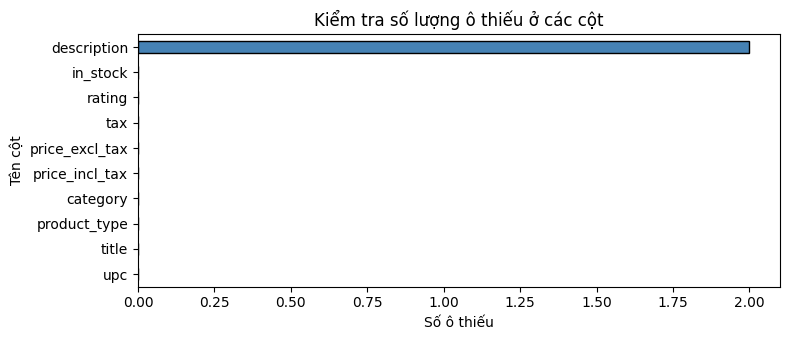

Danh sách các bản ghi bị thiếu mô tả (description):


,upc,title,category,rating,price_excl_tax,stock_quantity
160,efc3768127714ec3,The Bridge to Consciousness: I'm Writing the B...,Default,3,32.00,15
995,cd2a2a70dd5d176d,Alice in Wonderland (Alice's Adventures in Won...,Classics,1,55.53,1


Số bản ghi có chênh lệch bất thường giữa (Giá trước thuế + Thuế) và Giá sau thuế: 0


In [23]:
# Chuyển các chuỗi rỗng về NaN để thống kê chính xác dữ liệu khuyết
df_kiem_tra = df.replace("", np.nan)

print("Số dòng trùng hoàn toàn:", int(df_kiem_tra.duplicated().sum()))
if "upc" in df_kiem_tra.columns:
    print("Số mã UPC bị trùng lặp:", int(df_kiem_tra["upc"].duplicated().sum()))
if "title" in df_kiem_tra.columns:
    print("Số tiêu đề sách (title) trùng tên nhau:", int(df_kiem_tra["title"].duplicated().sum()))

thieu = df_kiem_tra.isna().sum().sort_values(ascending=False)
thieu_co_gia_tri = thieu[thieu > 0]
print("Tổng số ô thiếu trên toàn bộ dữ liệu:", int(thieu.sum()))
print("Số cột có dữ liệu thiếu:", int((thieu > 0).sum()))

if len(thieu_co_gia_tri) > 0:
    display(thieu_co_gia_tri.rename("Số ô thiếu").to_frame())
    
    plt.figure(figsize=(8, 3.5))
    thieu.head(10).sort_values().plot(kind="barh", color="steelblue", edgecolor="black")
    plt.title("Kiểm tra số lượng ô thiếu ở các cột")
    plt.xlabel("Số ô thiếu")
    plt.ylabel("Tên cột")
    plt.tight_layout()
    plt.show()
    
    print("Danh sách các bản ghi bị thiếu mô tả (description):")
    display(df[df_kiem_tra["description"].isna()][["upc", "title", "category", "rating", "price_excl_tax", "stock_quantity"]])
else:
    print("Không có ô thiếu nào trong tệp CSV này.")

# Kiểm tra tính nhất quán của giá và thuế
sai_lech_gia = ((df["price_excl_tax"] + df["tax"] - df["price_incl_tax"]).abs() > 1e-4).sum()
print("Số bản ghi có chênh lệch bất thường giữa (Giá trước thuế + Thuế) và Giá sau thuế:", int(sai_lech_gia))

## 5. Thống kê mô tả các thuộc tính số

Bảng thống kê dưới đây trình bày các đại lượng mô tả quan trọng gồm: số lượng quan sát hợp lệ (`count`), trung bình cộng (`mean`), độ lệch chuẩn (`std`), giá trị nhỏ nhất (`min`), các mức tứ phân vị (`25%`, `50%`, `75%`) và giá trị lớn nhất (`max`).

Một số đặc điểm đáng chú ý của môi trường dữ liệu giả lập trên Books to Scrape:
- Cột `tax` và `num_reviews` có giá trị bằng `0` ở tất cả các bản ghi (độ lệch chuẩn bằng `0`). Do đó `price_excl_tax` và `price_incl_tax` hoàn toàn bằng nhau trên mọi cuốn sách.
- Tất cả 1.000 cuốn sách đều có trạng thái `in_stock = True` với số lượng tồn kho dao động từ 1 đến 22 cuốn.


In [12]:
cot_so = [
    "rating", "price_excl_tax", "price_incl_tax", "tax",
    "stock_quantity", "num_reviews", "title_length",
    "desc_word_count", "inventory_value"
]
cot_so = [cot for cot in cot_so if cot in df.columns]
display(df[cot_so].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
rating,1000.0,2.92,1.43,1.00,2.00,3.00,4.00,5.00
price_excl_tax,1000.0,35.07,14.45,10.00,22.11,35.98,47.46,59.99
price_incl_tax,1000.0,35.07,14.45,10.00,22.11,35.98,47.46,59.99
tax,1000.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
stock_quantity,1000.0,8.59,5.65,1.00,3.00,7.00,14.00,22.00
num_reviews,1000.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
title_length,1000.0,39.10,25.75,2.00,19.00,35.00,53.00,204.00
desc_word_count,1000.0,236.38,107.56,0.00,177.00,222.50,279.00,1390.00
inventory_value,1000.0,300.19,247.13,10.64,105.46,225.09,454.63,1138.94


## 6. Phân bố Giá sách và Số lượng tồn kho

Các biểu đồ histogram dưới đây mô tả hình dáng phân bố của giá bán sách (`price_excl_tax`), số lượng tồn kho (`stock_quantity`) và độ dài phần mô tả (`desc_word_count`). Đường nét đứt trên biểu đồ đánh dấu vị trí giá trị trung vị (median) của từng thuộc tính.


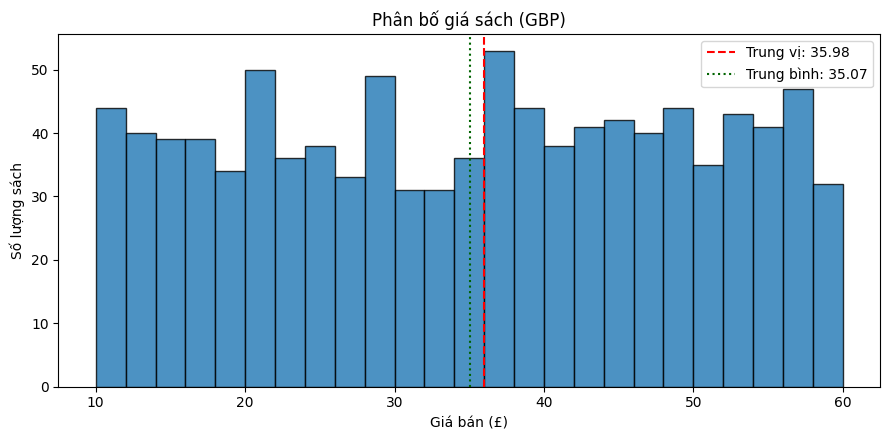

price_excl_tax -> Số quan sát: 1000 | Trung bình: 35.07 | Trung vị: 35.98


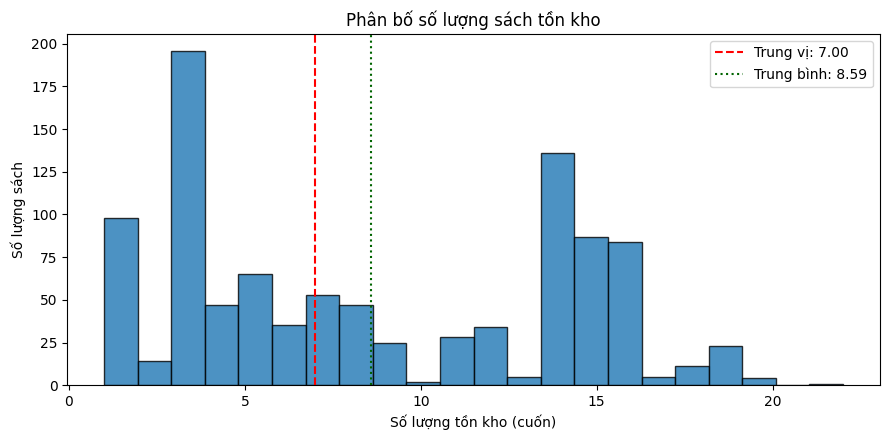

stock_quantity -> Số quan sát: 1000 | Trung bình: 8.59 | Trung vị: 7.00


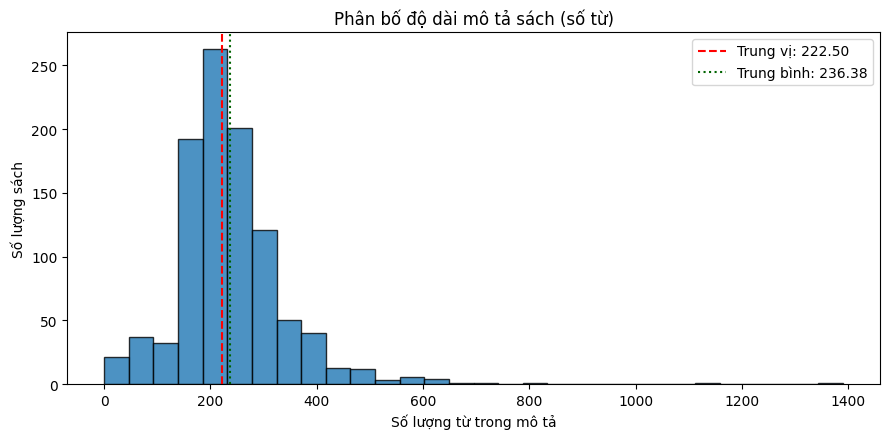

desc_word_count -> Số quan sát: 1000 | Trung bình: 236.38 | Trung vị: 222.50


In [13]:
cau_hinh_hist = [
    ("price_excl_tax", "Phân bố giá sách (GBP)", "Giá bán (£)", 25),
    ("stock_quantity", "Phân bố số lượng sách tồn kho", "Số lượng tồn kho (cuốn)", 22),
    ("desc_word_count", "Phân bố độ dài mô tả sách (số từ)", "Số lượng từ trong mô tả", 30)
]

for cot, tieu_de, nhan_x, so_bins in cau_hinh_hist:
    if cot in df.columns:
        gia_tri = df[cot].dropna()
        trung_vi = gia_tri.median()
        trung_binh = gia_tri.mean()
        
        plt.figure(figsize=(9, 4.5))
        plt.hist(gia_tri, bins=so_bins, edgecolor="black", alpha=0.8)
        plt.axvline(trung_vi, color="red", linestyle="--", linewidth=1.5, label=f"Trung vị: {trung_vi:.2f}")
        plt.axvline(trung_binh, color="darkgreen", linestyle=":", linewidth=1.5, label=f"Trung bình: {trung_binh:.2f}")
        plt.title(tieu_de)
        plt.xlabel(nhan_x)
        plt.ylabel("Số lượng sách")
        plt.legend()
        plt.tight_layout()
        plt.show()
        print(f"{cot} -> Số quan sát: {len(gia_tri)} | Trung bình: {trung_binh:.2f} | Trung vị: {trung_vi:.2f}")

## 7. Tần suất các thể loại sách (Category)

Bộ dữ liệu bao gồm 50 danh mục thể loại (`category`) khác nhau. Biểu đồ thanh ngang dưới đây thể hiện 15 thể loại chiếm số lượng đầu sách lớn nhất trên hệ thống. Hai nhãn mang tính mặc định của hệ thống sandbox là `Default` và `Add a comment` cũng xuất hiện với tần suất khá cao bên cạnh các thể loại sách thực tế như `Nonfiction`, `Sequential Art` hay `Fiction`.


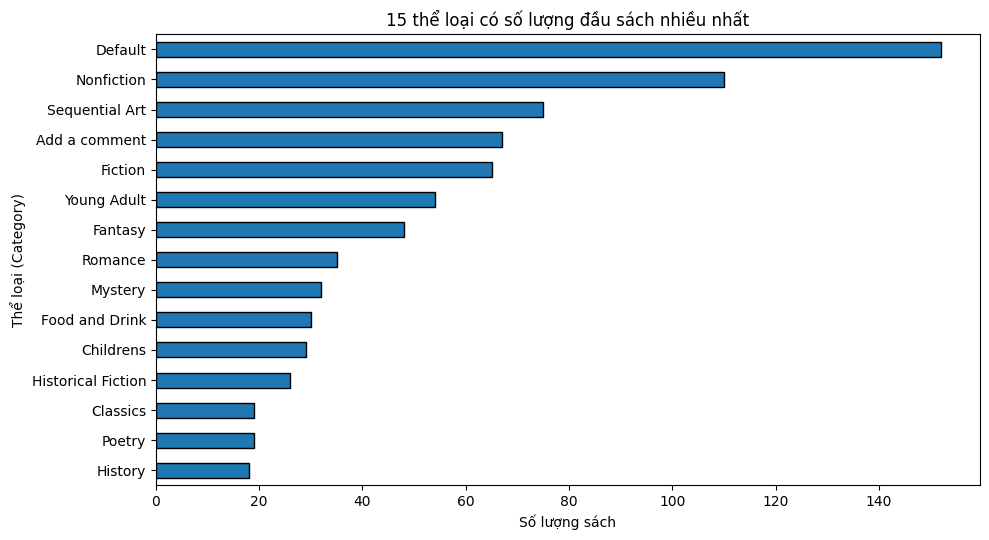

,Số lượng sách,Tỷ lệ (%),Giá trung bình (£)
category,,,
Default,152,15.2,34.39
Nonfiction,110,11.0,34.26
Sequential Art,75,7.5,34.57
Add a comment,67,6.7,35.80
Fiction,65,6.5,36.07
Young Adult,54,5.4,35.45
Fantasy,48,4.8,39.59
Romance,35,3.5,33.93
Mystery,32,3.2,31.72


In [15]:
if "category" in df.columns:
    dem_the_loai = df["category"].value_counts()
    top_15_the_loai = dem_the_loai.head(15)
    
    plt.figure(figsize=(10, 5.5))
    top_15_the_loai.sort_values().plot(kind="barh", edgecolor="black")
    plt.title("15 thể loại có số lượng đầu sách nhiều nhất")
    plt.xlabel("Số lượng sách")
    plt.ylabel("Thể loại (Category)")
    plt.tight_layout()
    plt.show()
    
    bang_the_loai = pd.DataFrame({
        "Số lượng sách": top_15_the_loai,
        "Tỷ lệ (%)": (top_15_the_loai / len(df) * 100).round(2),
        "Giá trung bình (£)": df.groupby("category")["price_excl_tax"].mean().loc[top_15_the_loai.index].round(2)
    })
    display(bang_the_loai)
else:
    print("Không tìm thấy cột category.")

## 8. Phân bố mức đánh giá sao (Rating)

Cột `rating` lưu trữ điểm đánh giá của sách theo thang nguyên từ 1 đến 5 sao. Biểu đồ cột dưới đây minh họa số lượng sách ở từng mức sao để kiểm tra xem điểm đánh giá có bị lệch về phía tích cực hay phân bố đồng đều.


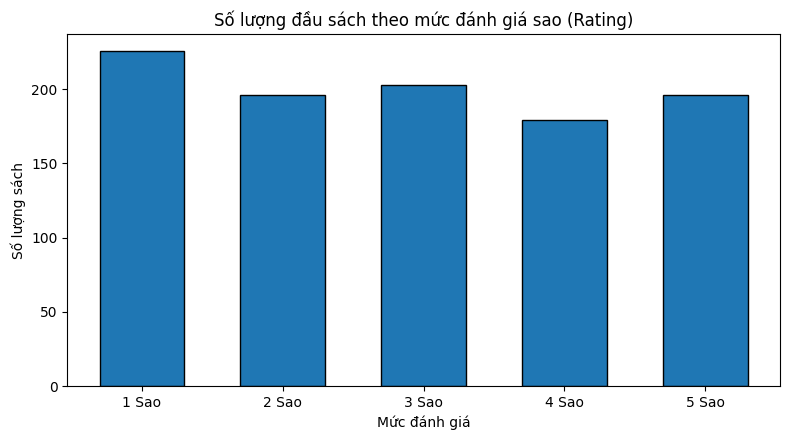

,Số lượng sách,Tỷ lệ (%),Giá trung bình (£),Tồn kho trung bình
rating,,,,
1 Sao,226,22.6,34.56,8.36
2 Sao,196,19.6,34.81,8.77
3 Sao,203,20.3,34.69,8.36
4 Sao,179,17.9,36.09,8.88
5 Sao,196,19.6,35.37,8.62


In [16]:
ten_rating = {
    1: "1 Sao",
    2: "2 Sao",
    3: "3 Sao",
    4: "4 Sao",
    5: "5 Sao"
}

if "rating" in df.columns:
    dem_rating = df["rating"].value_counts().sort_index()
    nhan_hien_thi = [ten_rating.get(int(muc), f"{muc} Sao") for muc in dem_rating.index]
    
    plt.figure(figsize=(8, 4.5))
    plt.bar(nhan_hien_thi, dem_rating.values, edgecolor="black", width=0.6)
    plt.title("Số lượng đầu sách theo mức đánh giá sao (Rating)")
    plt.xlabel("Mức đánh giá")
    plt.ylabel("Số lượng sách")
    plt.tight_layout()
    plt.show()
    
    bang_rating = pd.DataFrame({
        "Số lượng sách": dem_rating.rename(index=ten_rating),
        "Tỷ lệ (%)": (dem_rating.rename(index=ten_rating) / len(df) * 100).round(2),
        "Giá trung bình (£)": df.groupby("rating")["price_excl_tax"].mean().rename(index=ten_rating).round(2),
        "Tồn kho trung bình": df.groupby("rating")["stock_quantity"].mean().rename(index=ten_rating).round(2)
    })
    display(bang_rating)
else:
    print("Không tìm thấy cột rating.")

## 9. Mối liên hệ giữa Giá sách, Số lượng tồn kho và Độ dài mô tả

Biểu đồ phân tán (Scatter Plot) được sử dụng để kiểm tra trực quan mối quan hệ giữa giá sách (`price_excl_tax`) với số lượng tồn kho (`stock_quantity`), cũng như giữa giá sách với độ dài văn bản mô tả (`desc_word_count`). Mỗi điểm trên đồ thị đại diện cho một đầu sách trong dataset.


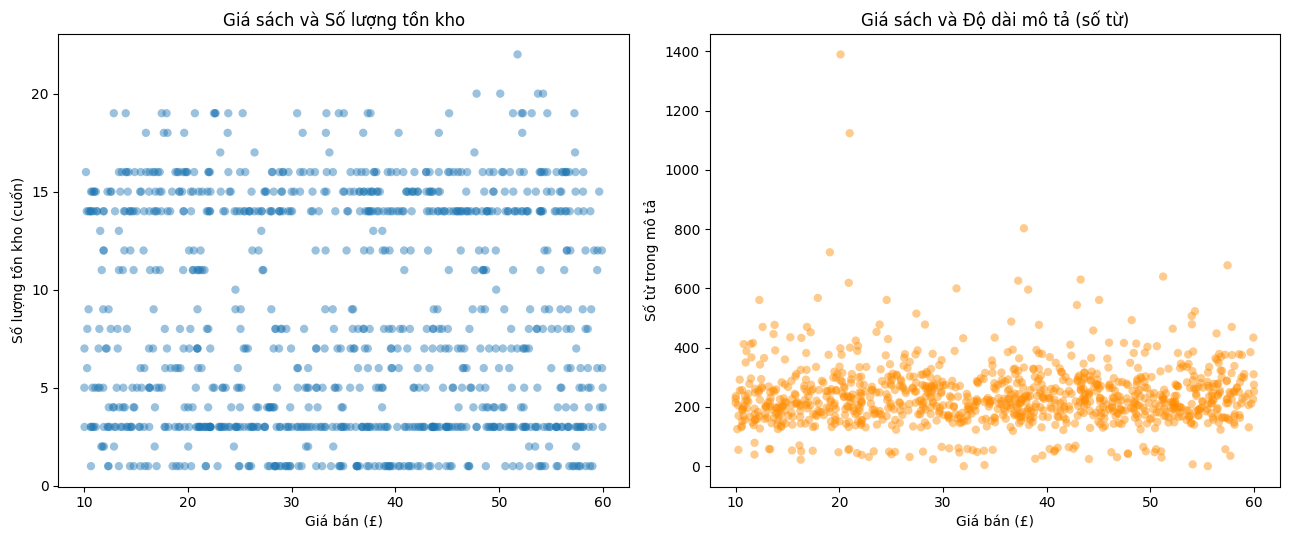

Số điểm dữ liệu được vẽ: 1000


In [17]:
if "price_excl_tax" in df.columns and "stock_quantity" in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    
    axes[0].scatter(df["price_excl_tax"], df["stock_quantity"], alpha=0.45, edgecolors="none")
    axes[0].set_title("Giá sách và Số lượng tồn kho")
    axes[0].set_xlabel("Giá bán (£)")
    axes[0].set_ylabel("Số lượng tồn kho (cuốn)")
    
    axes[1].scatter(df["price_excl_tax"], df["desc_word_count"], alpha=0.45, color="darkorange", edgecolors="none")
    axes[1].set_title("Giá sách và Độ dài mô tả (số từ)")
    axes[1].set_xlabel("Giá bán (£)")
    axes[1].set_ylabel("Số từ trong mô tả")
    
    plt.tight_layout()
    plt.show()
    print("Số điểm dữ liệu được vẽ:", len(df))

## 10. So sánh phân bố Giá sách theo Đánh giá sao và Thể loại

Biểu đồ hộp (Boxplot) giúp so sánh trung vị, khoảng tứ phân vị (IQR) và biên độ dao động của giá sách (`price_excl_tax`) giữa 5 nhóm đánh giá sao (`rating`), đồng thời so sánh mức giá giữa 10 thể loại sách phổ biến nhất (có từ 25 đầu sách trở lên).


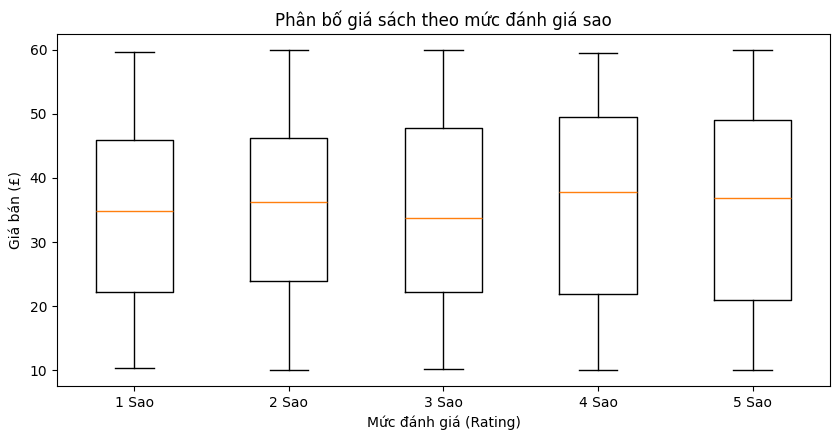

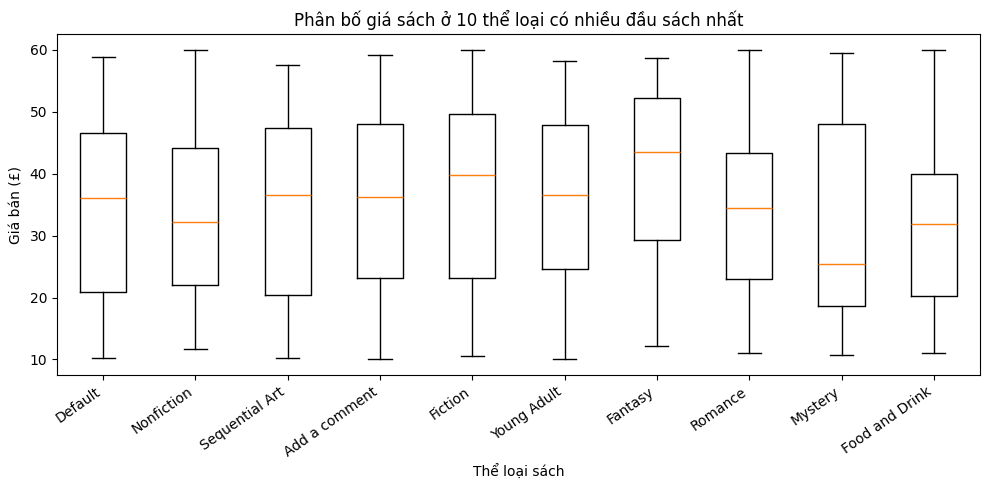

In [18]:
if "price_excl_tax" in df.columns and "rating" in df.columns:
    du_lieu_rating_box = []
    nhan_rating_box = []
    for muc in sorted(df["rating"].dropna().unique()):
        nhom_gia = df.loc[df["rating"] == muc, "price_excl_tax"].dropna()
        if len(nhom_gia) >= 5:
            du_lieu_rating_box.append(nhom_gia)
            nhan_rating_box.append(f"{int(muc)} Sao")
            
    plt.figure(figsize=(8.5, 4.5))
    plt.boxplot(du_lieu_rating_box, tick_labels=nhan_rating_box, showfliers=False)
    plt.title("Phân bố giá sách theo mức đánh giá sao")
    plt.xlabel("Mức đánh giá (Rating)")
    plt.ylabel("Giá bán (£)")
    plt.tight_layout()
    plt.show()

if "price_excl_tax" in df.columns and "category" in df.columns:
    top_10_cat = df["category"].value_counts().head(10).index.tolist()
    du_lieu_cat_box = [df.loc[df["category"] == cat, "price_excl_tax"].dropna() for cat in top_10_cat]
    
    plt.figure(figsize=(10, 5))
    plt.boxplot(du_lieu_cat_box, tick_labels=top_10_cat, showfliers=False)
    plt.title("Phân bố giá sách ở 10 thể loại có nhiều đầu sách nhất")
    plt.xlabel("Thể loại sách")
    plt.ylabel("Giá bán (£)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

## 11. Tương quan giữa các biến số

Ma trận tương quan tuyến tính Pearson được tính toán trên các biến số có phương sai khác 0 (loại bỏ 2 cột hằng số là `tax` và `num_reviews` vì độ lệch chuẩn bằng 0 sẽ sinh ra giá trị `NaN` khi chia hiệp phương sai).

Hệ số tương quan nằm trong đoạn từ `-1` đến `1`:
- Hai cột `price_excl_tax` và `price_incl_tax` có tương quan tuyệt đối bằng `1.00` do thuế bằng 0.
- Tương quan giữa `inventory_value` với `stock_quantity` (`0.82`) và `price_excl_tax` (`0.50`) ở mức cao vì đây là biến tích số của hai đại lượng này.
- Giữa `rating`, `price_excl_tax` và `stock_quantity` có hệ số tương quan xấp xỉ `0`, phản ánh đúng bản chất dữ liệu được khởi tạo ngẫu nhiên độc lập trên website sandbox.


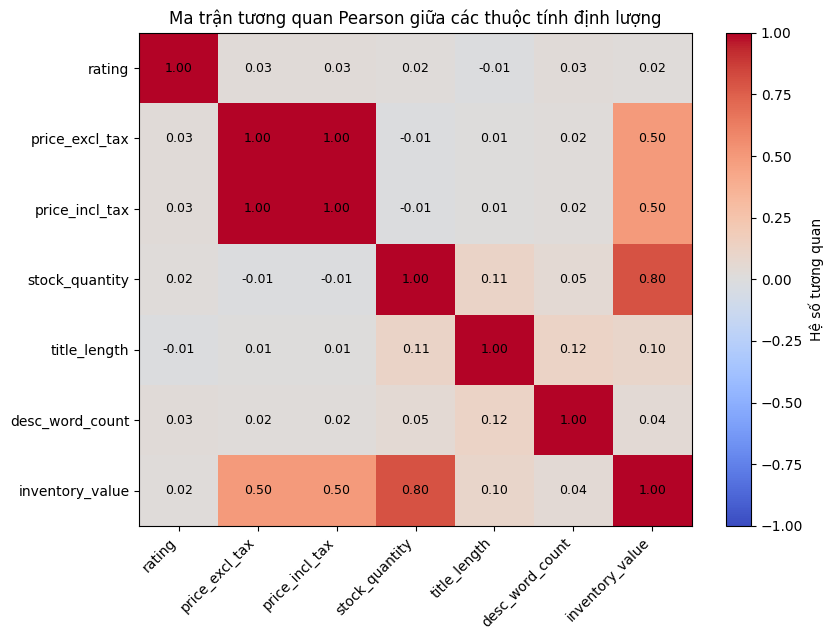

,rating,price_excl_tax,price_incl_tax,stock_quantity,title_length,desc_word_count,inventory_value
rating,1.000,0.028,0.028,0.016,-0.011,0.025,0.022
price_excl_tax,0.028,1.000,1.000,-0.011,0.007,0.023,0.498
price_incl_tax,0.028,1.000,1.000,-0.011,0.007,0.023,0.498
stock_quantity,0.016,-0.011,-0.011,1.000,0.111,0.047,0.799
title_length,-0.011,0.007,0.007,0.111,1.000,0.121,0.096
desc_word_count,0.025,0.023,0.023,0.047,0.121,1.000,0.040
inventory_value,0.022,0.498,0.498,0.799,0.096,0.040,1.000


In [19]:
cot_tuong_quan = [
    "rating", "price_excl_tax", "price_incl_tax",
    "stock_quantity", "title_length", "desc_word_count", "inventory_value"
]
cot_tuong_quan = [c for c in cot_tuong_quan if c in df.columns and df[c].nunique() > 1]

if len(cot_tuong_quan) >= 2:
    corr = df[cot_tuong_quan].corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)
    ax.set_title("Ma trận tương quan Pearson giữa các thuộc tính định lượng")
    
    for i in range(len(corr.index)):
        for j in range(len(corr.columns)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="black", fontsize=9)
            
    fig.colorbar(image, ax=ax, label="Hệ số tương quan")
    plt.tight_layout()
    plt.show()
    display(corr.round(3))
else:
    print("Không đủ cột số biến thiên để tính ma trận tương quan.")

## 12. Phân tích giá trị tồn kho theo đầu sách và thể loại

Mục này khảo sát sâu hơn cột `inventory_value` (`price_incl_tax * stock_quantity`) nhằm ước lượng quy mô vốn tồn kho của cửa hàng sách giả lập, đồng thời xác định các đầu sách và danh mục thể loại chiếm tỷ trọng giá trị tồn kho cao nhất.


Tổng số bản in tồn kho toàn hệ thống: 8,585 cuốn
Tổng giá trị tồn kho ước tính: £300,188.27


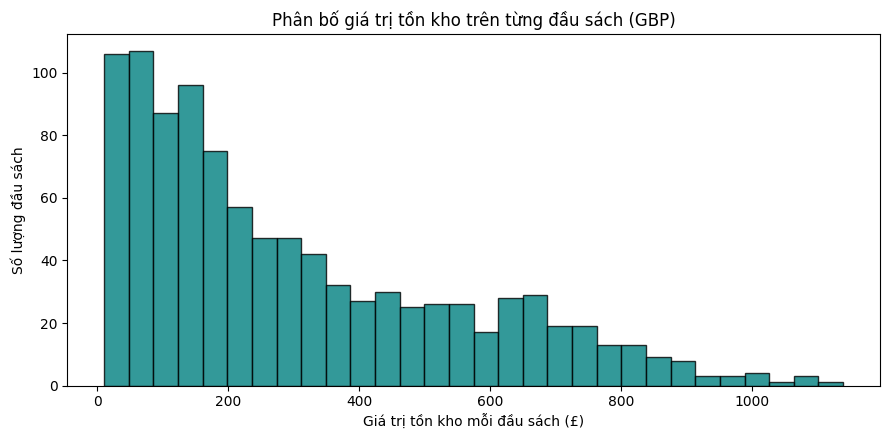

Top 10 cuốn sách có tổng giá trị tồn kho cao nhất:


,upc,title,category,rating,price_incl_tax,stock_quantity,inventory_value
0,a897fe39b1053632,A Light in the Attic,Poetry,3,51.77,22,1138.94
15,deda3e61b9514b83,Our Band Could Be Your Life: Scenes from the A...,Music,3,57.25,19,1087.75
4,4165285e1663650f,Sapiens: A Brief History of Humankind,History,5,54.23,20,1084.60
1,90fa61229261140a,Tipping the Velvet,Historical Fiction,1,53.74,20,1074.80
25,9528d0948525bf5f,Birdsong: A Story in Pictures,Childrens,3,54.64,19,1038.16
27,904208d6aa64b655,Aladdin and His Wonderful Lamp,Default,3,53.13,19,1009.47
2,6957f44c3847a760,Soumission,Fiction,1,50.10,20,1002.00
13,3b1c02bac2a429e6,Scott Pilgrim's Precious Little Life (Scott Pi...,Sequential Art,5,52.29,19,993.51
9,1dfe412b8ac00530,The Black Maria,Poetry,1,52.15,19,990.85
18,a18a4f574854aced,Libertarianism for Beginners,Politics,2,51.33,19,975.27


Top 10 thể loại có tổng giá trị hàng tồn kho lớn nhất:


,So_dau_sach,Tong_ton_kho,Tong_gia_tri_GBP
category,,,
Default,152,1345,46916.77
Nonfiction,110,975,32123.26
Sequential Art,75,686,23286.02
Fiction,65,588,21445.99
Add a comment,67,516,18315.24
Young Adult,54,464,16714.84
Fantasy,48,372,14591.77
Food and Drink,30,319,10347.51
Mystery,32,290,9496.48


In [20]:
if "inventory_value" in df.columns:
    tong_so_ban_in = int(df["stock_quantity"].sum())
    tong_gia_tri_kho = float(df["inventory_value"].sum())
    print(f"Tổng số bản in tồn kho toàn hệ thống: {tong_so_ban_in:,} cuốn")
    print(f"Tổng giá trị tồn kho ước tính: £{tong_gia_tri_kho:,.2f}")
    
    plt.figure(figsize=(9, 4.5))
    plt.hist(df["inventory_value"], bins=30, edgecolor="black", color="teal", alpha=0.8)
    plt.title("Phân bố giá trị tồn kho trên từng đầu sách (GBP)")
    plt.xlabel("Giá trị tồn kho mỗi đầu sách (£)")
    plt.ylabel("Số lượng đầu sách")
    plt.tight_layout()
    plt.show()
    
    print("Top 10 cuốn sách có tổng giá trị tồn kho cao nhất:")
    top_10_sach_kho = df.sort_values("inventory_value", ascending=False).head(10)[
        ["upc", "title", "category", "rating", "price_incl_tax", "stock_quantity", "inventory_value"]
    ]
    display(top_10_sach_kho)
    
    print("Top 10 thể loại có tổng giá trị hàng tồn kho lớn nhất:")
    kho_theo_the_loai = df.groupby("category").agg(
        So_dau_sach=("upc", "count"),
        Tong_ton_kho=("stock_quantity", "sum"),
        Tong_gia_tri_GBP=("inventory_value", "sum")
    ).sort_values("Tong_gia_tri_GBP", ascending=False).head(10)
    kho_theo_the_loai["Tong_gia_tri_GBP"] = kho_theo_the_loai["Tong_gia_tri_GBP"].round(2)
    display(kho_theo_the_loai)

## 13. Tổng hợp kết quả khảo sát

Đoạn mã dưới đây tổng hợp tự động các chỉ số quan trọng được rút ra từ bộ dữ liệu `books_to_scrape.csv`, tổng hợp lại toàn bộ bức tranh về quy mô, độ sạch và đặc trưng phân phối của dataset.


In [22]:
so_dong, so_cot = df.shape
so_o_thieu = int(df.replace("", np.nan).isna().sum().sum())
so_dong_trung = int(df.duplicated().sum())

print(f"- Quy mô bộ dữ liệu (sau khi thêm đặc trưng): {so_dong:,} dòng và {so_cot:,} cột.")
print(f"- Tổng số ô thiếu dữ liệu: {so_o_thieu:,} ô (nằm ở cột description).")
print(f"- Số dòng trùng lặp hoàn toàn: {so_dong_trung:,}.")
print(f"- Số mã định danh UPC duy nhất: {df['upc'].nunique():,}.")
print(f"- Số lượng thể loại sách (category): {df['category'].nunique():,}.")
print(f"- Khoảng giá bán sách: từ £{df['price_excl_tax'].min():.2f} đến £{df['price_excl_tax'].max():.2f} (Trung bình: £{df['price_excl_tax'].mean():.2f}, Trung vị: £{df['price_excl_tax'].median():.2f}).")
print(f"- Khoảng tồn kho mỗi đầu sách: từ {df['stock_quantity'].min()} đến {df['stock_quantity'].max()} cuốn (Tổng cộng: {df['stock_quantity'].sum():,} cuốn).")
print(f"- Tổng giá trị hàng tồn kho ước tính: £{df['inventory_value'].sum():,.2f}.")

print("\nDiễn giải:")
print("1. Cột 'upc' đóng vai trò khóa chính định danh sản phẩm, không có bản ghi trùng lặp.")
print("2. Cột 'tax' và 'num_reviews' có giá trị bằng 0 cố định trên toàn bộ 1.000 cuốn sách.")
print("3. Giá sách phân bố khá đồng đều trong khoảng £10.00 - £59.99, không có ngoại lệ.")
print("4. Điểm đánh giá (rating) phân bố tương đối cân bằng ở cả 5 mức sao và hầu như độc lập tuyến tính với giá bán cũng như số lượng tồn kho.")

- Quy mô bộ dữ liệu (sau khi thêm đặc trưng): 1,000 dòng và 17 cột.
- Tổng số ô thiếu dữ liệu: 2 ô (nằm ở cột description).
- Số dòng trùng lặp hoàn toàn: 0.
- Số mã định danh UPC duy nhất: 1,000.
- Số lượng thể loại sách (category): 50.
- Khoảng giá bán sách: từ £10.00 đến £59.99 (Trung bình: £35.07, Trung vị: £35.98).
- Khoảng tồn kho mỗi đầu sách: từ 1 đến 22 cuốn (Tổng cộng: 8,585 cuốn).
- Tổng giá trị hàng tồn kho ước tính: £300,188.27.

Diễn giải:
1. Cột 'upc' đóng vai trò khóa chính định danh sản phẩm, không có bản ghi trùng lặp.
2. Cột 'tax' và 'num_reviews' có giá trị bằng 0 cố định trên toàn bộ 1.000 cuốn sách.
3. Giá sách phân bố khá đồng đều trong khoảng £10.00 - £59.99, không có ngoại lệ.
4. Điểm đánh giá (rating) phân bố tương đối cân bằng ở cả 5 mức sao và hầu như độc lập tuyến tính với giá bán cũng như số lượng tồn kho.


## 14. Kết luận

Báo cáo đã hoàn thành việc khảo sát cấu trúc, kiểm tra chất lượng và phân tích thống kê mô tả cho bộ dữ liệu **Books to Scrape** thu thập qua pipeline ETL. Dữ liệu có độ hoàn thiện và tính nhất quán rất cao: đủ 1.000 bản ghi ứng với 1.000 mã UPC duy nhất, không có bản ghi trùng lặp và chỉ khuyết thông tin mô tả ở 2 cuốn sách.

Qua các bảng thống kê và biểu đồ trực quan hóa, có thể nhận thấy rõ đặc trưng của một website thương mại điện tử giả lập: mức giá bán (`£10.00` – `£59.99`) và điểm đánh giá (`1` – `5` sao) tuân theo phân phối gần như đồng đều, đồng thời không tồn tại sự tương quan tuyến tính giữa giá bán, điểm đánh giá và lượng hàng tồn kho. Bên cạnh đó, một số trường mặc định như thuế (`tax = 0`), số lượng đánh giá (`num_reviews = 0`), loại sản phẩm (`product_type = Books`) và trạng thái còn hàng (`in_stock = True`) giữ giá trị hằng số trên toàn tập dữ liệu.